# Projeto: Detecção de Fraudes em Transações com Cartão de Crédito

# Introdução
Este projeto tem como objetivo desenvolver modelos de Machine Learning capazes de identificar transações fraudulentas.

O principal desafio consiste no forte desbalanceamento entre transações legítimas e fraudulentas, exigindo estratégias específicas de preparação dos dados e avaliação dos modelos.

Serão avaliados três algoritmos: Regressão Logística, Random Forest e XGBoost.

Ao final, será realizada uma comparação entre os modelos, otimização do limiar de decisão e análise das variáveis que mais influenciam as previsões.

# Importação das Bibliotecas

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    precision_recall_curve,
    average_precision_score
)

import warnings
warnings.filterwarnings("ignore")


# Carregamento dos dados

In [17]:
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(url)

df.head()

#Observe que na tabela já temos a discriminação das transações que são fraudes e que não são. ("Class")

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# Análise inicial

In [18]:
# Dimensões do dataset
print("Dimensões:", df.shape)

# Informações das colunas
df.info()

# Verificação de valores ausentes
print("Valores ausentes:", df.isnull().sum().sum())

# Estatísticas descritivas
df.describe()

Dimensões: (284807, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null 

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


# Análise do desbalanceamento

Uma característica importante do dataset é o forte desbalanceamento entre as classes.

Essa condição pode prejudicar a avaliação dos algoritmos, pois um modelo pode apresentar alta acurácia mesmo sem conseguir identificar adequadamente as transações fraudulentas.

Isso se dá por conta da leitura de padrões que o algoritmo faz, como existe uma quantidade muito maior de transações legítimas o algorítmo pode acabar deixando classificando transações fraudulentas como legítimas.

Por isso, será analisada a distribuição das classes antes do treinamento.

In [19]:
# Quantidade de transações por classe
print(df["Class"].value_counts())

# Distribuição percentual
print(df["Class"].value_counts(normalize=True) * 100)

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


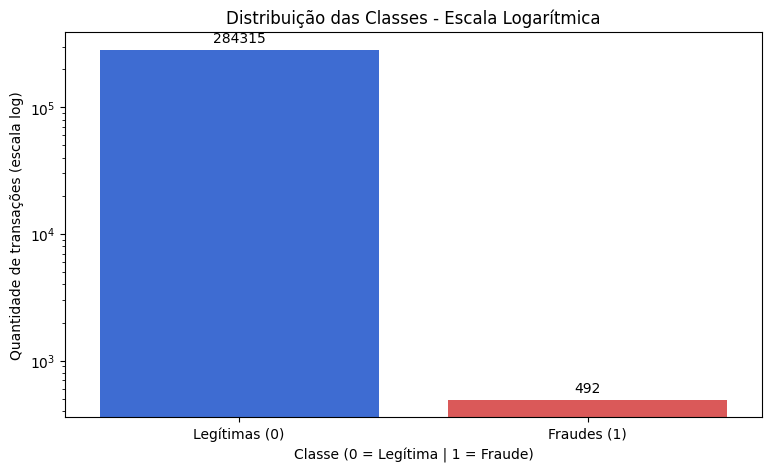

In [20]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df,
    x="Class",
    hue="Class",
    palette={0: "#2563EB", 1: "#EF4444"},
    legend=False
)

ax.set_yscale("log")

plt.title("Distribuição das Classes - Escala Logarítmica")
plt.xlabel("Classe (0 = Legítima | 1 = Fraude)")
plt.ylabel("Quantidade de transações (escala log)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.xticks([0, 1], ["Legítimas (0)", "Fraudes (1)"])

plt.show()

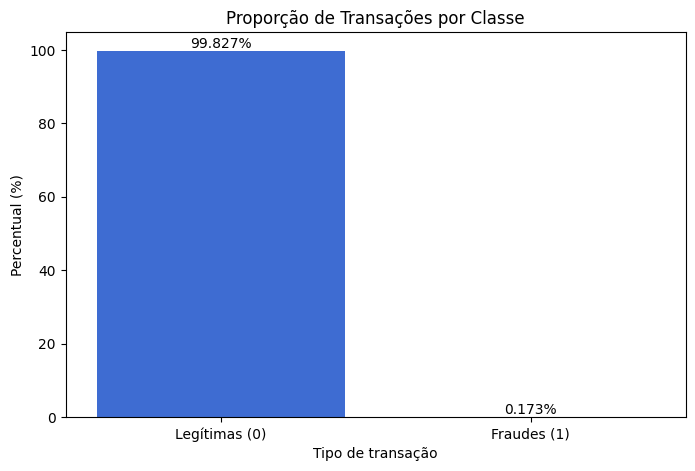

In [21]:
proporcao = df["Class"].value_counts(normalize=True) * 100

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=["Legítimas (0)", "Fraudes (1)"],
    y=[proporcao[0], proporcao[1]],
    hue=["Legítimas (0)", "Fraudes (1)"],
    palette=["#2563EB", "#EF4444"],
    legend=False
)

plt.title("Proporção de Transações por Classe")
plt.ylabel("Percentual (%)")
plt.xlabel("Tipo de transação")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f%%")

plt.show()

# Preparação dos dados
Nesta etapa, serão realizadas transformações e ajustes nas variáveis para preparar o conjunto de dados para o treinamento dos modelos.

Será criada uma transformação logarítmica da variável Amount (valor da transação), seguida da separação entre as variáveis preditoras (X) e a variável-alvo (y).

Posteriormente, os dados serão divididos em conjuntos de treinamento e teste, preservando a proporção original das classes.

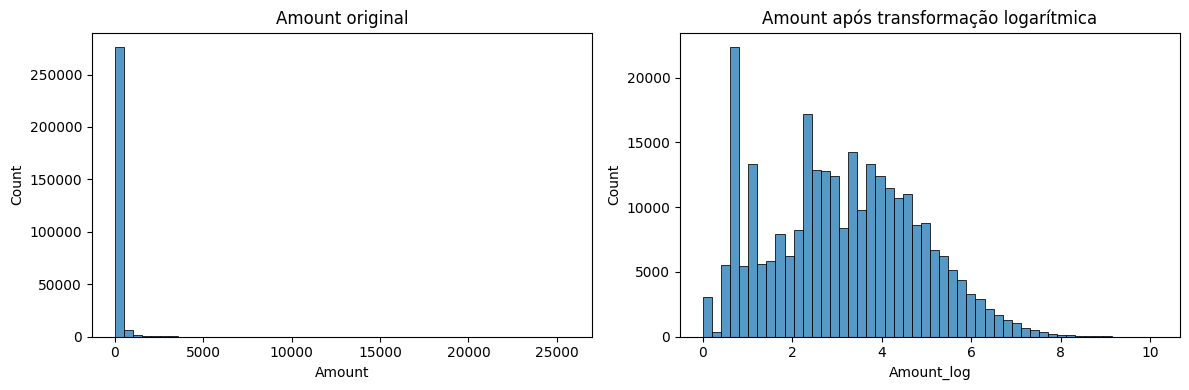

In [22]:
# Criando uma variável com transformação logarítmica
df["Amount_log"] = np.log1p(df["Amount"])

# Comparando as distribuições
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["Amount"], bins=50, ax=axes[0])
axes[0].set_title("Amount original")

sns.histplot(df["Amount_log"], bins=50, ax=axes[1])
axes[1].set_title("Amount após transformação logarítmica")

plt.tight_layout()
plt.show()

In [23]:
X = df.drop("Class", axis=1)
y = df["Class"]

# Divisão de treino x teste

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

Treino: (227845, 31)
Teste: (56962, 31)


# Padronização das variáveis com a biblioteca StandardScaler
Ela coloca as variáveis em escalas comparáveis, evitando que diferenças de magnitude prejudiquem modelos como a Regressão Logística.

In [25]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

- fit_transform: calcula média e desvio-padrão usando os dados de treino e aplica a transformação.



- transform: aplica os mesmos parâmetros ao teste, sem recalculá-los.

# Treinamento dos modelos
Nesta etapa, serão treinados três algoritmos de classificação: Regressão Logística, Random Forest e XGBoost. O objetivo é comparar o desempenho de diferentes abordagens na identificação de transações fraudulentas, considerando o desbalanceamento entre as classes.

# Regressão Logística
Estima a probabilidade de algo pertencer a uma classe. No caso, a probabilidade de uma transação ser fraude ou não.



In [26]:
modelo_lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

modelo_lr.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# Random Forest
Combina muitas árvores de decisão e deixa elas "votarem" no resultado final.
Como a Random Forest resolve isso?

1.   Ela treina centenas de árvores, cada uma com uma amostra aleatória das transações
2.   Em cada divisão, cada árvore considera só um subconjunto aleatório das variáveis.
3. Na hora de prever, todas as árvores votam e vale a maioria (ou a média das probabilidades).

Como cada árvore enxerga os dados de um jeito diferente, os erros individuais tendem a se cancelar, e o resultado fica mais estável e preciso do que o de uma árvore isolada.

In [27]:
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train_scaled, y_train)

RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42)

# XGBoost
Esse modelo também usa muitas árvores de decisão, mas de um jeito bem diferente do Random Forest.

No Random Forest, as árvores são treinadas de forma independente e votam no final. No XGBoost, elas são treinadas uma depois da outra, e cada nova árvore tenta corrigir os erros das anteriores, como uma progressão de melhoria contínua.


In [29]:
modelo_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

modelo_xgb.fit(X_train_scaled, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

# Análise da importância das variáveis
Nesta etapa, será analisada a importância das variáveis utilizadas pelo modelo XGBoost durante o processo de classificação.

A análise permite identificar quais atributos tiveram maior contribuição relativa para as previsões do modelo.

Será utilizado o atributo `feature_importances_`, disponibilizado pelo XGBoost, para ordenar as variáveis de acordo com sua importância estimada.

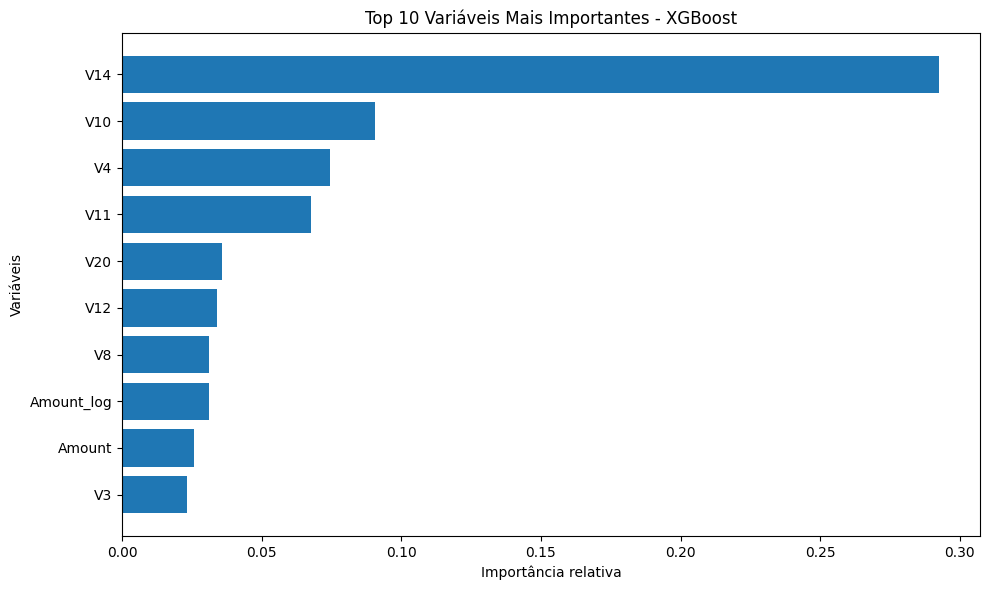

In [41]:

# Extraindo a importância das variáveis
importancias = pd.Series(
    modelo_xgb.feature_importances_,
    index=X_train.columns
)

# Ordenando as variáveis pela importância
importancias = importancias.sort_values(
    ascending=False
)

# Selecionando as 10 variáveis mais importantes
top_10 = importancias.head(10)

# Criando o gráfico
plt.figure(figsize=(10, 6))

plt.barh(
    top_10.index[::-1],
    top_10.values[::-1]
)

plt.title("Top 10 Variáveis Mais Importantes - XGBoost")
plt.xlabel("Importância relativa")
plt.ylabel("Variáveis")

plt.tight_layout()
plt.show()



### Interpretação da importância das variáveis

A análise da importância das variáveis permite observar quais atributos foram mais relevantes para as decisões do modelo XGBoost.

As variáveis com maior importância apresentaram maior contribuição relativa para o processo de classificação realizado pelo modelo.

É importante destacar que essa medida não representa uma relação causal e não significa que uma variável, isoladamente, determine a ocorrência de uma fraude.

Além disso, as variáveis V1 a V28 correspondem a componentes obtidos por transformação PCA, não possuindo uma interpretação financeira direta no dataset.


# Avaliação dos modelos

In [30]:
#Previsões

y_pred_lr = modelo_lr.predict(X_test_scaled)
y_pred_rf = modelo_rf.predict(X_test_scaled)
y_pred_xgb = modelo_xgb.predict(X_test_scaled)

In [31]:
#Comparação de resultados

modelos = {
    "Regressão Logística": y_pred_lr,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

for nome, previsoes in modelos.items():
    print(f"\nModelo: {nome}")
    print(classification_report(y_test, previsoes))
    print("Matriz de confusão:")
    print(confusion_matrix(y_test, previsoes))


Modelo: Regressão Logística
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

Matriz de confusão:
[[55483  1381]
 [    8    90]]

Modelo: Random Forest
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.76      0.85        98

    accuracy                           1.00     56962
   macro avg       0.98      0.88      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Matriz de confusão:
[[56861     3]
 [   24    74]]

Modelo: XGBoost
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.56      0.87      0.68        98

    accurac

Como interpretar os resultados acima?

Na saída, observe principalmente a linha da classe 1, que representa as fraudes:

*   Precision: entre as transações sinalizadas como fraude, quantas realmente eram fraude?
*   Recall: entre todas as fraudes existentes, quantas o modelo conseguiu identificar?
*   F1-score: equilíbrio entre precision e recall.
*   Accuracy: percentual geral de acertos. Neste dataset, pode ser enganosa devido ao desbalanceamento.

### Análise comparativa dos modelos

A Regressão Logística apresentou alto recall (0,92), mas baixa precisão (0,06), indicando uma quantidade elevada de falsos positivos.

O Random Forest obteve o melhor F1-score (0,85) e a maior precisão (0,96), demonstrando maior equilíbrio entre identificação de fraudes e redução de alertas incorretos.

O XGBoost apresentou recall de 0,87, identificando 85 das 98 fraudes presentes no conjunto de teste, mas gerando 68 falsos positivos.

Os resultados demonstram que a escolha do modelo depende do equilíbrio desejado entre a identificação de fraudes e o custo de investigações desnecessárias.

# Ajuste do threshold (limiar) do XGBoost

Vamos utilizar a curva Precision-Recall para avaliar como precision e recall mudam conforme alteramos o limiar e após isso avaliaremos também a maximização do F1-Score.

Podemos ver no gráfico gerado que o limiar ideal para um equilíbrio entre precision e recall fica entre 0,8 e 1.

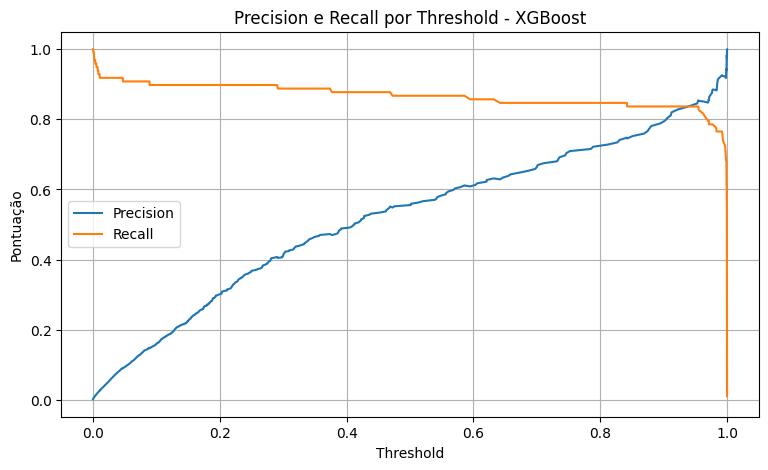

In [32]:
y_proba_xgb = modelo_xgb.predict_proba(X_test_scaled)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_test, y_proba_xgb
)

plt.figure(figsize=(9, 5))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")

plt.xlabel("Threshold")
plt.ylabel("Pontuação")
plt.title("Precision e Recall por Threshold - XGBoost")
plt.legend()
plt.grid()
plt.show()

O código abaixo cria uma tabela com precision, recall e F1-score para cada threshold testado e seleciona aquele com maior F1-score.

In [33]:
resultados_limiar = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision[:-1],
    "Recall": recall[:-1]
})

resultados_limiar["F1-score"] = (
    2 * resultados_limiar["Precision"] * resultados_limiar["Recall"]
    / (resultados_limiar["Precision"] + resultados_limiar["Recall"])
)

melhor_limiar = resultados_limiar.loc[
    resultados_limiar["F1-score"].idxmax()
]

melhor_limiar

,56018
Threshold,0.954468
Precision,0.854167
Recall,0.836735
F1-score,0.845361


In [34]:
print("Melhor threshold:", melhor_limiar["Threshold"])
print("Precision:", melhor_limiar["Precision"])
print("Recall:", melhor_limiar["Recall"])
print("F1-score:", melhor_limiar["F1-score"])

Melhor threshold: 0.9544679522514343
Precision: 0.8541666666666666
Recall: 0.8367346938775511
F1-score: 0.845360824742268


O threshold encontrado foi 0,9545, com F1-score de 84,54%.

Isso significa que o XGBoost só classifica uma transação como fraude quando sua probabilidade estimada é igual ou superior a aproximadamente 95,45%.

Comparado ao threshold padrão de 0,5, o modelo fica mais rigoroso.

# Aplicando novo threshold


In [35]:
threshold_otimizado = melhor_limiar["Threshold"]

y_pred_xgb_otimizado = (
    y_proba_xgb >= threshold_otimizado
).astype(int)

In [36]:
print(classification_report(
    y_test,
    y_pred_xgb_otimizado
))

print("Matriz de confusão:")
print(confusion_matrix(
    y_test,
    y_pred_xgb_otimizado
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.85      0.84      0.85        98

    accuracy                           1.00     56962
   macro avg       0.93      0.92      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Matriz de confusão:
[[56850    14]
 [   16    82]]


# Comparação XGBoost antes e depois da mudança no threshold

XGBoost padrão
-----------------------------------------------  

Precision	55,56%

Recall	86,73%

F1-score	67,73%

Falsos positivos	68

Fraudes identificadas	85

XGBoost otimizado
---------------------------------------------------
Precision	85,42%

Recall	83,67%

F1-score	84,54%

Falsos positivos	14

Fraudes identificadas	82


Com o ajuste, o modelo:
----------------------------------
- Reduziu os falsos positivos de 68 para 14, uma queda de aproximadamente 79%.
- Identificou 82 das 98 fraudes.
- Deixou passar 16 fraudes.
- Aumentou o F1-score de 67,73% para 84,54%.

O resultado demonstra que o ajuste do threshold permitiu melhorar o equilíbrio entre a identificação de fraudes e a redução de alertas incorretos.


# Comparação final dos modelos
Nesta etapa, os resultados dos modelos serão comparados com base nas métricas de precision, recall e F1-score para a classe fraudulenta.

In [38]:
comparacao = pd.DataFrame({
    "Modelo": [
        "Regressão Logística",
        "Random Forest",
        "XGBoost",
        "XGBoost Otimizado"
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb),
        precision_score(y_test, y_pred_xgb_otimizado)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb),
        recall_score(y_test, y_pred_xgb_otimizado)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb),
        f1_score(y_test, y_pred_xgb_otimizado)
    ]
})

comparacao.sort_values(
    by="F1-score",
    ascending=False
)

comparacao_formatada = comparacao.copy()

for coluna in ["Precision", "Recall", "F1-score"]:
    comparacao_formatada[coluna] = (
        comparacao_formatada[coluna] * 100
    ).round(2).astype(str) + "%"

comparacao_formatada

,Modelo,Precision,Recall,F1-score
0,Regressão Logística,6.12%,91.84%,11.47%
1,Random Forest,96.1%,75.51%,84.57%
2,XGBoost,55.56%,86.73%,67.73%
3,XGBoost Otimizado,85.42%,83.67%,84.54%



| Modelo | Threshold | Precision | Recall | F1-score | Fraudes identificadas | Fraudes não identificadas | Falsos positivos |
|---|---:|---:|---:|---:|---:|---:|---:|
| Regressão Logística | 0,50 | 6,12% | 91,84% | 11,47% | 90 | 8 | 1.381 |
| Random Forest | 0,50 | 96,10% | 75,51% | 84,57% | 74 | 24 | 3 |
| XGBoost | 0,50 | 55,56% | 86,73% | 67,73% | 85 | 13 | 68 |
| XGBoost Otimizado | 0,9545 | 85,42% | 83,67% | 84,54% | 82 | 16 | 14 |


# Conclusão

Este projeto teve como objetivo desenvolver modelos de Machine Learning para identificar transações fraudulentas em cartões de crédito.

Durante o desenvolvimento, foram realizadas análises exploratórias, tratamento e transformação dos dados, divisão entre treino e teste e treinamento de três algoritmos: Regressão Logística, Random Forest e XGBoost.

Os resultados demonstraram a importância de avaliar diferentes métricas em problemas com classes desbalanceadas. Embora a Regressão Logística tenha apresentado alto recall, sua baixa precisão resultou em muitos falsos positivos.

O Random Forest apresentou o melhor F1-score entre os modelos com threshold padrão. Já o XGBoost, após o ajuste do threshold para aproximadamente 0,9545, alcançou precision de 85,42%, recall de 83,67% e F1-score de 84,54%.

O projeto evidenciou que a escolha do modelo e do limiar de classificação influencia diretamente o equilíbrio entre a identificação de fraudes e a redução de alertas incorretos.

A escolha do modelo deve considerar os custos associados aos falsos negativos, que representam fraudes não identificadas, e aos falsos positivos, que representam transações legítimas sinalizadas incorretamente.